# Association rules (Unit 3, method 2)
Which tag, price and Early Access combinations go with the **Strong** reception tier? FP-Growth on the 1,191 training games, FDR control, then one check on the 299 test games. Source: `src/analysis/association_rules.py`; outputs in `reports/results/`.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
RES = ROOT / "reports/results"
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.3f}".format
s = json.load(open(RES / "association_rules_summary.json"))
print(f"{s['n_train']} training games, {s['n_test']} test games, {s['n_items']} items (tags, price band, Early Access)")
print(f"Strong is the tier for {s['train_tier_rates']['Strong']:.1%} of training games, Struggling for {s['train_tier_rates']['Struggling']:.1%}")
print(f"{s['candidate_rules']:,} candidate rules -> {s['strong_rules_count']} Strong and {s['struggling_rules_count']} Struggling rules pass FDR control (q < {s['settings']['fdr']})")

1191 training games, 299 test games, 137 items (tags, price band, Early Access)
Strong is the tier for 35.3% of training games, Struggling for 13.9%
4,715 candidate rules -> 95 Strong and 0 Struggling rules pass FDR control (q < 0.1)


## Support, confidence and lift, checked by hand
Recompute one rule from the cleaned data: *Pixel Graphics + Retro + Shooter => Strong*.

In [2]:
g = pd.read_parquet(ROOT / "data/processed/games_clean.parquet", columns=["appid", "tags"])
t = pd.read_parquet(ROOT / "data/processed/features/game_targets.parquet", columns=["appid", "split", "tier", "eligible"])
gf = pd.read_parquet(ROOT / "data/processed/features/game_features.parquet", columns=["appid", "split"])
d = g.merge(t.drop(columns="split"), on="appid").merge(gf, on="appid").query("eligible == 1")
tr = d[d.split == "train"]
has = tr.tags.fillna("").apply(lambda x: {"Pixel Graphics", "Retro", "Shooter"} <= set(x.split(";")))
n, hits, base = int(has.sum()), int((tr[has].tier == "Strong").sum()), (tr.tier == "Strong").mean()
print(f"support    = {hits}/{len(tr)} = {hits / len(tr):.3f}   (games with the combination AND Strong)")
print(f"confidence = {hits}/{n} = {hits / n:.2f}   (share of those games that are Strong)")
print(f"lift       = {hits / n:.2f} / {base:.3f} = {hits / n / base:.2f}   (against the Strong rate of all training games)")

support    = 20/1191 = 0.017   (games with the combination AND Strong)
confidence = 20/25 = 0.80   (share of those games that are Strong)
lift       = 0.80 / 0.353 = 2.26   (against the Strong rate of all training games)


## The rules that pass FDR control

{'stable': 45, 'too few test games': 29, 'unstable': 21}


,rule,n_antecedent,support,confidence,lift,q_value,test_n_antecedent,test_confidence
0,Procedural Generation + Retro,43,0.024,0.674,1.908,0.005,14.000,0.571
1,Arcade + Retro + Roguelite,52,0.029,0.673,1.904,0.005,11.000,0.545
2,price <$5 + 2D + Procedural Generation,36,0.020,0.667,1.886,0.013,11.000,0.455
3,Arcade + Pixel Graphics + Retro,50,0.028,0.660,1.867,0.005,12.000,0.667
4,2D + Perma Death + Procedural Generation,32,0.018,0.656,1.857,0.029,12.000,0.750
5,price <$5 + Pixel Graphics + Procedural Genera...,29,0.016,0.655,1.853,0.046,12.000,0.417
6,2D + Puzzle + Roguelike,37,0.020,0.649,1.835,0.020,10.000,0.700
7,price <$5 + Retro,62,0.033,0.629,1.780,0.005,23.000,0.435


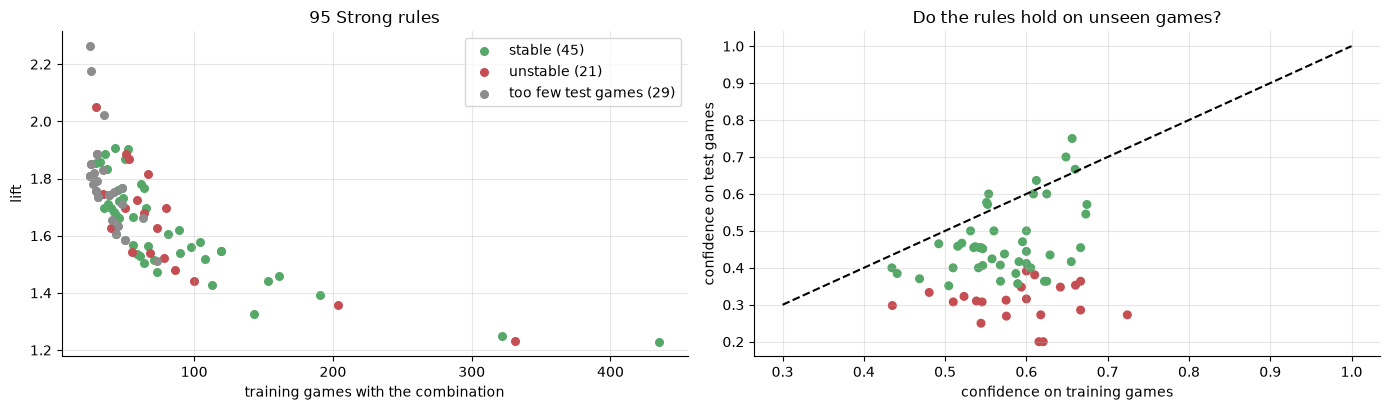

In [3]:
r = pd.read_csv(RES / "association_rules_strong.csv")
print(r.stability.value_counts().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for k, c in [("stable", "#55A868"), ("unstable", "#C44E52"), ("too few test games", "#8C8C8C")]:
    q = r[r.stability == k]; ax[0].scatter(q.n_antecedent, q.lift, c=c, label=f"{k} ({len(q)})", s=30)
ax[0].set(xlabel="training games with the combination", ylabel="lift", title="95 Strong rules"); ax[0].legend()
ok = r[r.stability != "too few test games"]
ax[1].scatter(ok.confidence, ok.test_confidence, c=np.where(ok.stability == "stable", "#55A868", "#C44E52"), s=30); ax[1].plot([.3, 1], [.3, 1], "k--")
ax[1].set(xlabel="confidence on training games", ylabel="confidence on test games", title="Do the rules hold on unseen games?")
plt.tight_layout()
nice = lambda a: a.replace("tag:", "").replace("price:", "price ")
display(r[r.is_stable].sort_values("lift", ascending=False).head(8).assign(rule=lambda x: x.antecedents_str.map(nice))[["rule", "n_antecedent", "support", "confidence", "lift", "q_value", "test_n_antecedent", "test_confidence"]].reset_index(drop=True))

## Comparing configurations
Same transactions, same train and test games, thresholds and algorithm changed (`src/analysis/association_rule_comparison.py`).

,configuration,candidate_rules,strong_rules,mean_support,mean_confidence,mean_lift,share_holding_on_test,rules_with_enough_test_games
0,"FP-Growth, min support 25 games, up to 3 items...",4715,95,0.032,0.595,1.683,0.682,66
1,"Apriori, same thresholds",4715,95,0.032,0.595,1.683,0.682,66
2,"FP-Growth, min support 15 games (looser)",5363,107,0.027,0.653,1.848,0.661,56
3,"FP-Growth, min support 40 games (stricter)",3281,69,0.038,0.565,1.599,0.695,59
4,"FP-Growth, pairs only (max 2 items)",1580,41,0.043,0.564,1.595,0.833,30
5,"FP-Growth, keeping evaluative tags",5225,131,0.029,0.597,1.689,0.693,88


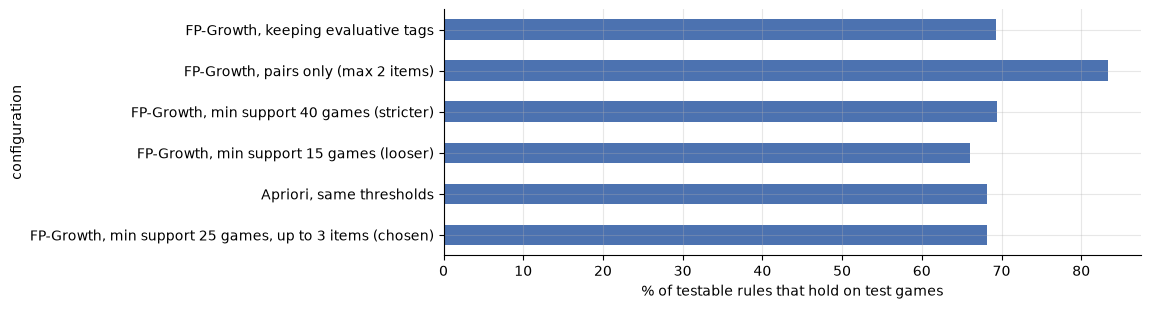

In [4]:
cmp = pd.read_csv(RES / "association_rule_configuration_comparison.csv")
display(cmp[["configuration", "candidate_rules", "strong_rules", "mean_support", "mean_confidence", "mean_lift", "share_holding_on_test", "rules_with_enough_test_games"]])
ax = cmp.set_index("configuration")[["share_holding_on_test"]].mul(100).plot.barh(figsize=(9, 3.2), legend=False, color="#4C72B0", xlabel="% of testable rules that hold on test games")

- FP-Growth and Apriori return the same 95 rules (Apriori is a little slower); the algorithm is not the choice that matters.
- Lower support finds more rules with a higher mean lift but a lower share that hold on test games; higher support finds fewer, more reliable rules. 25 games balances the two.
- No configuration produces a Struggling rule: risk is not a matter of tags alone.
- Rules are associations in observational data, with small supports (30 to 60 training games). They are hypotheses for a studio, not recipes.